# Exact-split baseline comparison
This notebook reports only experiments measured on `fnews-research-v1`. NewsCLIPpings is excluded because it has zero valid local pairs.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
root = Path('../reports/experiments/research_dataset_baselines')
metrics = json.loads((root / 'metrics.json').read_text())
assert metrics['split_counts'] == {'train': 2353, 'validate': 933, 'test': 947}
comparison = pd.read_csv(root / 'comparison.csv')
display(comparison)
print('Selected by validation macro-F1:', metrics['selected_model'])
display(pd.DataFrame([metrics['selected_model_test']]).drop(columns=['per_class', 'confusion_matrix']))

,model,accuracy,macro_f1
0,tfidf_svm,0.720257,0.717136
1,pretrained_text_frozen,0.691318,0.688974
2,resnet18_frozen,0.693462,0.686088
3,random_stratified,0.500536,0.496552
4,majority,0.595927,0.373405


Selected by validation macro-F1: tfidf_svm


,accuracy,macro_f1
0,0.731785,0.727029


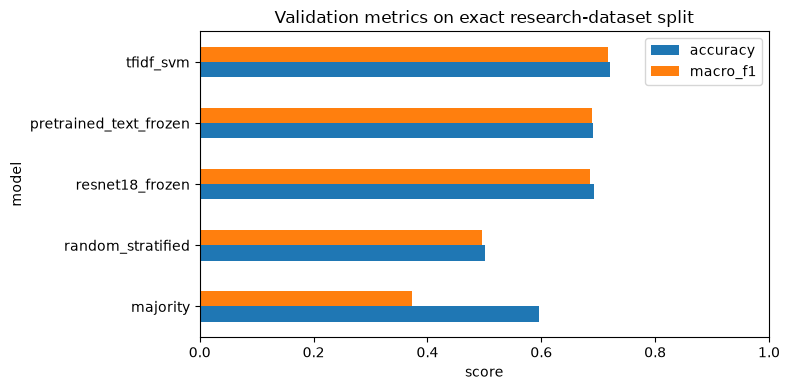

tfidf_svm [[385, 171], [90, 287]]
resnet18_frozen [[395, 161], [125, 252]]
pretrained_text_frozen [[363, 193], [95, 282]]


In [2]:
ax = comparison.sort_values('macro_f1').plot.barh(x='model', y=['accuracy', 'macro_f1'], figsize=(8,4), title='Validation metrics on exact research-dataset split')
ax.set_xlim(0, 1); ax.set_xlabel('score'); plt.tight_layout(); plt.show()
for name in ['tfidf_svm', 'resnet18_frozen', 'pretrained_text_frozen']:
    print(name, metrics['results'][name]['validation']['confusion_matrix'])

## Protocol
The test split was evaluated exactly once for the validation-selected TF-IDF+SVM model. CLIP retrieval was attempted but did not complete; no CLIP score is reported. Frozen encoders were used because the validation gains did not justify fine-tuning in this baseline stage.